In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import mutual_info_classif
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
CSV_CANDIDATES = [Path('soil_fertility_classification_1000.csv'),
                  Path('upload/soil_fertility_classification_1000.csv'),
                  Path('Dataset/soil_fertility_classification_1000.csv')]
dataset_path = next((p for p in CSV_CANDIDATES if p.is_file()), None)
if dataset_path is None:
    raise FileNotFoundError('Place soil_fertility_classification_1000.csv next to this notebook.')
df = pd.read_csv(dataset_path)
FEATURES = ['pH', 'Electrical_Conductivity_dS_m', 'Organic_Carbon_g_kg',
            'Available_N_kg_ha', 'Available_P_kg_ha', 'Available_K_kg_ha',
            'Sulphur_mg_kg', 'Zinc_mg_kg', 'Boron_mg_kg', 'Iron_mg_kg',
            'Manganese_mg_kg', 'Copper_mg_kg']
CLASSES = ['Low Fertility', 'Medium Fertility', 'High Fertility']
print('Loaded:', dataset_path, '| Shape:', df.shape)

Loaded: soil_fertility_classification_1000.csv | Shape: (1000, 20)


In [2]:
display(df.head())
print('Rows:', len(df), 'Columns:', df.shape[1])
print(df.dtypes)
print('Target classes:', df['Fertility_Class'].unique())

,Sample_ID,Source_Calibration,State,District,Soil_Type,Crop,pH,Electrical_Conductivity_dS_m,Organic_Carbon_g_kg,Available_N_kg_ha,Available_P_kg_ha,Available_K_kg_ha,Sulphur_mg_kg,Zinc_mg_kg,Boron_mg_kg,Iron_mg_kg,Manganese_mg_kg,Copper_mg_kg,Fertility_Score,Fertility_Class
0,SFC-0001,Indian laboratory soil datasets (AgriNet/Krish...,Uttar Pradesh,Lucknow,Alluvial,Cotton,6.91,0.150,12.08,169.90,32.32,54.05,15.46,1.34,1.13,16.65,7.20,1.00,47.15,Medium Fertility
1,SFC-0002,Indian laboratory soil dataset calibrated exte...,Maharashtra,Nashik,Red,Cotton,6.61,0.424,10.85,170.47,31.70,126.62,11.17,0.87,1.39,15.67,6.15,1.36,46.47,Medium Fertility
2,SFC-0003,Indian laboratory soil dataset calibrated exte...,Karnataka,Mysuru,Loamy,Pulses,7.52,0.596,5.51,130.75,32.14,381.20,10.98,0.51,0.83,21.16,5.31,0.69,39.27,Low Fertility
3,SFC-0004,Indian laboratory soil dataset calibrated exte...,Punjab,Ludhiana,Clay Loam,Rice,7.03,0.257,9.48,202.66,49.68,77.23,20.79,0.76,1.60,38.51,9.07,0.60,59.38,Medium Fertility
4,SFC-0005,Indian laboratory soil datasets (AgriNet/Krish...,Uttar Pradesh,Bareilly,Loamy,Vegetables,7.17,0.282,15.65,189.12,24.58,213.50,17.32,1.35,0.47,25.92,17.15,1.20,61.00,Medium Fertility


Rows: 1000 Columns: 20
Sample_ID                        object
Source_Calibration               object
State                            object
District                         object
Soil_Type                        object
Crop                             object
pH                              float64
Electrical_Conductivity_dS_m    float64
Organic_Carbon_g_kg             float64
Available_N_kg_ha               float64
Available_P_kg_ha               float64
Available_K_kg_ha               float64
Sulphur_mg_kg                   float64
Zinc_mg_kg                      float64
Boron_mg_kg                     float64
Iron_mg_kg                      float64
Manganese_mg_kg                 float64
Copper_mg_kg                    float64
Fertility_Score                 float64
Fertility_Class                  object
dtype: object
Target classes: ['Medium Fertility' 'Low Fertility' 'High Fertility']


In [3]:
clean = df.copy().replace(r'^\s*$', np.nan, regex=True)
for c in FEATURES + ['Fertility_Score']:
    clean[c] = pd.to_numeric(clean[c], errors='coerce')
duplicate_rows = int(clean.duplicated().sum())
duplicate_ids = int(clean['Sample_ID'].duplicated().sum())
invalid_ph = int((~clean['pH'].dropna().between(0, 14)).sum())
negative_measurements = int((clean[FEATURES[1:]] < 0).sum().sum())
expected_label = np.select([clean.Fertility_Score < 40, clean.Fertility_Score < 70],
                           [CLASSES[0], CLASSES[1]], default=CLASSES[2])
label_mismatch = int((expected_label != clean.Fertility_Class).sum())
print({'duplicate_rows': duplicate_rows, 'duplicate_ids': duplicate_ids,
       'invalid_pH': invalid_ph, 'negative_measurements': negative_measurements,
       'label_score_mismatches': label_mismatch})
if invalid_ph or negative_measurements or label_mismatch:
    raise ValueError('Invalid source data detected; review before modelling.')
clean = clean.drop_duplicates().dropna(subset=['Fertility_Class']).reset_index(drop=True)
print('Cleaned shape:', clean.shape)

{'duplicate_rows': 0, 'duplicate_ids': 0, 'invalid_pH': 0, 'negative_measurements': 0, 'label_score_mismatches': 0}
Cleaned shape: (1000, 20)


In [4]:
missing = clean.isna().sum()
display(missing.to_frame('Missing values'))
print('Total missing values:', int(missing.sum()))

,Missing values
Sample_ID,0
Source_Calibration,0
State,0
District,0
Soil_Type,0
Crop,0
pH,0
Electrical_Conductivity_dS_m,0
Organic_Carbon_g_kg,0
Available_N_kg_ha,0


Total missing values: 0


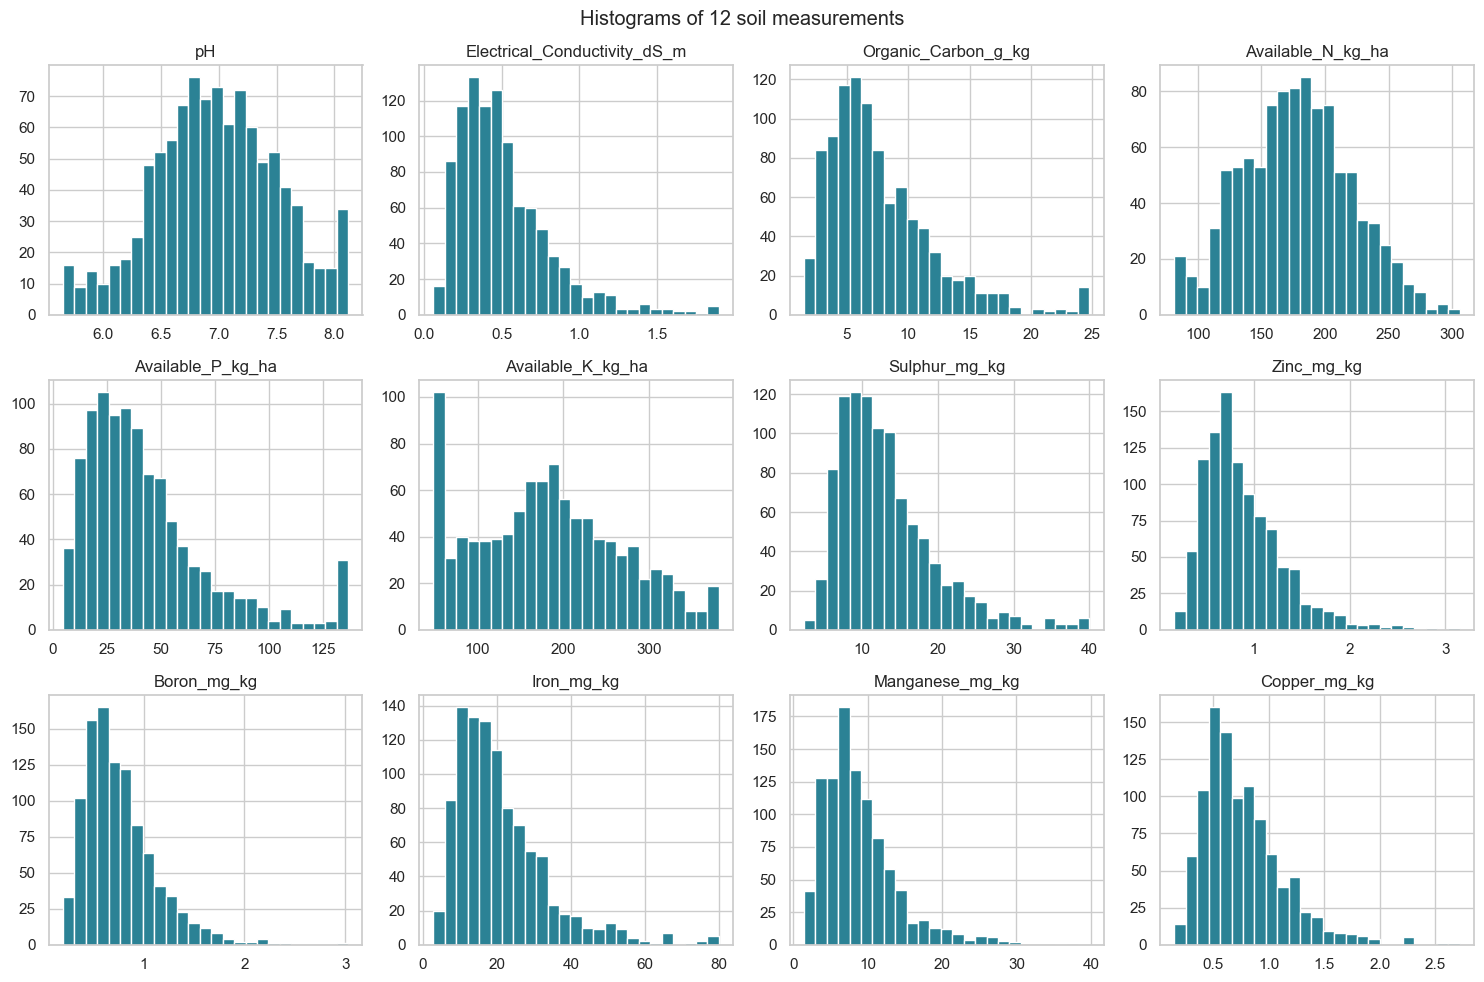

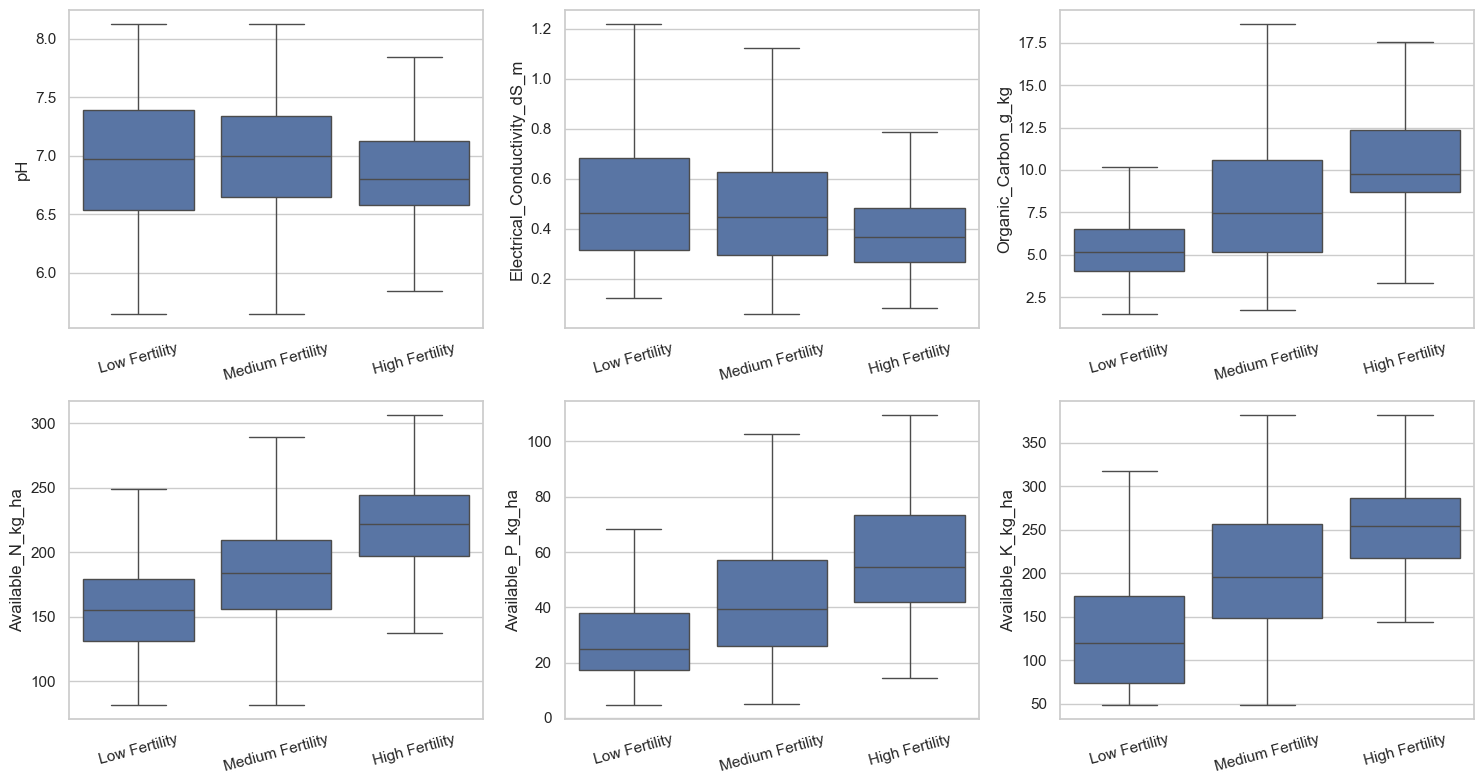

In [5]:
clean[FEATURES].hist(bins=25, figsize=(15, 10), layout=(3, 4), color='#2b8295')
plt.suptitle('Histograms of 12 soil measurements')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.flat, FEATURES[:6]):
    sns.boxplot(data=clean, x='Fertility_Class', y=c, order=CLASSES, ax=ax, showfliers=False)
    ax.tick_params(axis='x', rotation=15)
    ax.set_xlabel('')
plt.tight_layout()
plt.show()

,pH,Electrical_Conductivity_dS_m,Organic_Carbon_g_kg,Available_N_kg_ha,Available_P_kg_ha,Available_K_kg_ha,Sulphur_mg_kg,Zinc_mg_kg,Boron_mg_kg,Iron_mg_kg,Manganese_mg_kg,Copper_mg_kg
pH,1.00,-0.02,-0.00,0.03,0.04,-0.03,-0.00,-0.02,-0.01,0.01,0.00,0.01
Electrical_Conductivity_dS_m,-0.02,1.00,-0.04,0.03,-0.02,-0.02,-0.01,-0.01,-0.02,0.06,0.03,-0.02
Organic_Carbon_g_kg,-0.00,-0.04,1.00,-0.01,-0.02,-0.06,-0.00,-0.03,-0.03,-0.00,-0.01,-0.01
Available_N_kg_ha,0.03,0.03,-0.01,1.00,-0.04,0.03,-0.03,-0.04,0.02,-0.02,-0.03,-0.01
Available_P_kg_ha,0.04,-0.02,-0.02,-0.04,1.00,0.03,-0.02,0.01,0.06,0.02,-0.06,-0.04
Available_K_kg_ha,-0.03,-0.02,-0.06,0.03,0.03,1.00,0.06,-0.04,0.02,-0.03,-0.03,0.04
Sulphur_mg_kg,-0.00,-0.01,-0.00,-0.03,-0.02,0.06,1.00,0.03,0.00,0.06,-0.04,0.01
Zinc_mg_kg,-0.02,-0.01,-0.03,-0.04,0.01,-0.04,0.03,1.00,0.02,0.03,-0.02,-0.02
Boron_mg_kg,-0.01,-0.02,-0.03,0.02,0.06,0.02,0.00,0.02,1.00,0.02,-0.06,0.05
Iron_mg_kg,0.01,0.06,-0.00,-0.02,0.02,-0.03,0.06,0.03,0.02,1.00,-0.00,0.01


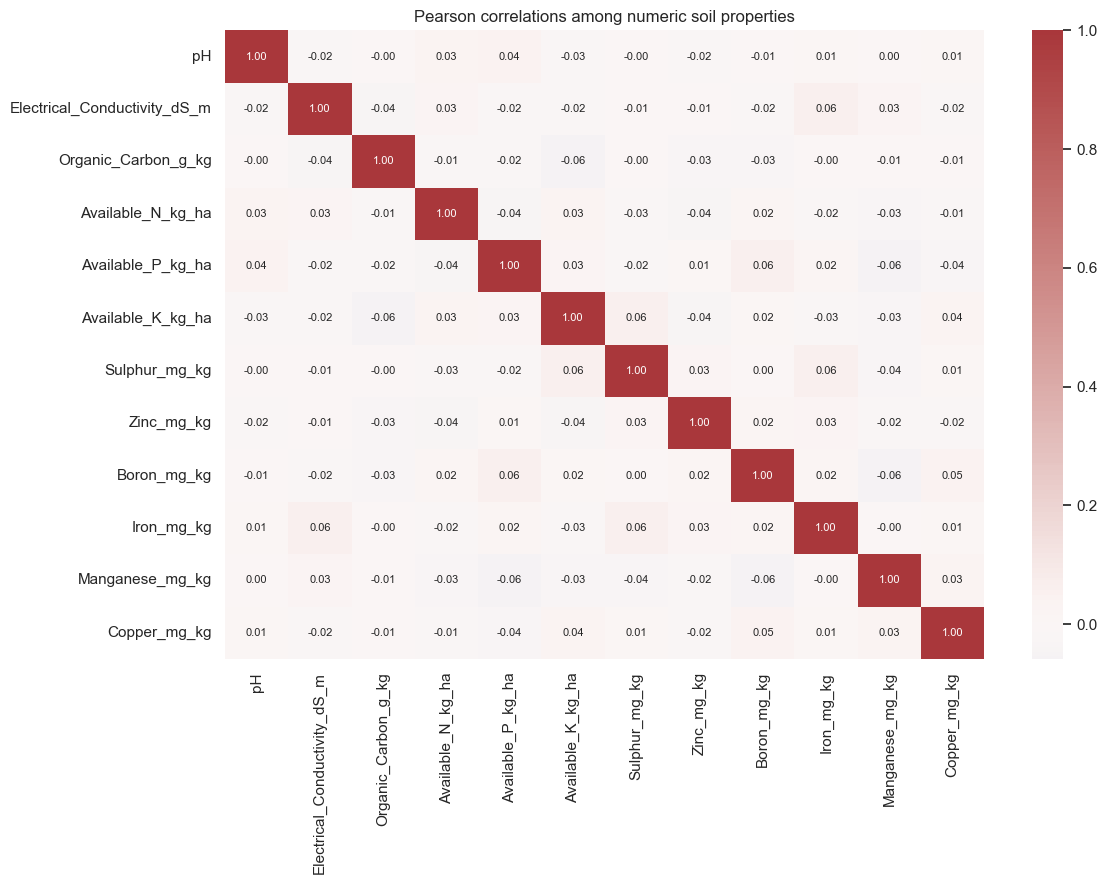

In [6]:
corr = clean[FEATURES].corr(method='pearson')
display(corr.round(2))
plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='vlag', center=0, annot_kws={'size': 8})
plt.title('Pearson correlations among numeric soil properties')
plt.tight_layout()
plt.show()

In [7]:
X, y = clean[FEATURES], clean['Fertility_Class']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)
screen_imputer = SimpleImputer(strategy='median')
X_train_screen = screen_imputer.fit_transform(X_train)
mutual_information = pd.Series(
    mutual_info_classif(X_train_screen, y_train, random_state=42),
    index=FEATURES, name='Mutual information').sort_values(ascending=False)
display(mutual_information.to_frame())
print('Selected features:', FEATURES)

,Mutual information
Available_N_kg_ha,0.123682
Available_K_kg_ha,0.118088
Organic_Carbon_g_kg,0.114772
Available_P_kg_ha,0.078077
Zinc_mg_kg,0.002271
pH,0.000000
Electrical_Conductivity_dS_m,0.000000
Sulphur_mg_kg,0.000000
Boron_mg_kg,0.000000
Iron_mg_kg,0.000000


Selected features: ['pH', 'Electrical_Conductivity_dS_m', 'Organic_Carbon_g_kg', 'Available_N_kg_ha', 'Available_P_kg_ha', 'Available_K_kg_ha', 'Sulphur_mg_kg', 'Zinc_mg_kg', 'Boron_mg_kg', 'Iron_mg_kg', 'Manganese_mg_kg', 'Copper_mg_kg']


In [8]:
print('Training:', X_train.shape, '| Test:', X_test.shape)
print('Training classes:\n', y_train.value_counts().reindex(CLASSES))
print('Testing classes:\n', y_test.value_counts().reindex(CLASSES))
print('Method: stratified 80/20 split; random_state=42')

Training: (800, 12) | Test: (200, 12)
Training classes:
 Fertility_Class
Low Fertility       255
Medium Fertility    477
High Fertility       68
Name: count, dtype: int64
Testing classes:
 Fertility_Class
Low Fertility        64
Medium Fertility    119
High Fertility       17
Name: count, dtype: int64
Method: stratified 80/20 split; random_state=42


In [9]:
def prep(scale=False):
    steps = [('imputer', SimpleImputer(strategy='median'))]
    if scale:
        steps.append(('standardize', StandardScaler()))
    return Pipeline(steps)

models = {
    'Decision Tree': Pipeline([('prep', prep()), ('classifier', DecisionTreeClassifier(
        max_depth=8, min_samples_leaf=3, random_state=42))]),
    'Random Forest': Pipeline([('prep', prep()), ('classifier', RandomForestClassifier(
        n_estimators=300, min_samples_leaf=2, class_weight='balanced_subsample',
        random_state=42, n_jobs=-1))]),
    'KNN': Pipeline([('prep', prep(True)), ('classifier', KNeighborsClassifier(n_neighbors=9))]),
    'SVM': Pipeline([('prep', prep(True)), ('classifier', SVC(
        kernel='rbf', C=3, gamma='scale', class_weight='balanced', random_state=42))]),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_results = {}
for name, pipeline in models.items():
    fold_scores = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring='f1_macro')
    cv_results[name] = (float(fold_scores.mean()), float(fold_scores.std()))
    pipeline.fit(X_train, y_train)
    print(f'{name:14s} training CV macro F1: {fold_scores.mean():.4f} ± {fold_scores.std():.4f}')

Decision Tree  training CV macro F1: 0.7503 ± 0.0256
Random Forest  training CV macro F1: 0.7868 ± 0.0173
KNN            training CV macro F1: 0.5931 ± 0.0373
SVM            training CV macro F1: 0.7747 ± 0.0341



 Decision Tree
                  precision    recall  f1-score   support

   Low Fertility       0.87      0.81      0.84        64
Medium Fertility       0.83      0.89      0.86       119
  High Fertility       0.58      0.41      0.48        17

        accuracy                           0.82       200
       macro avg       0.76      0.71      0.73       200
    weighted avg       0.82      0.82      0.82       200



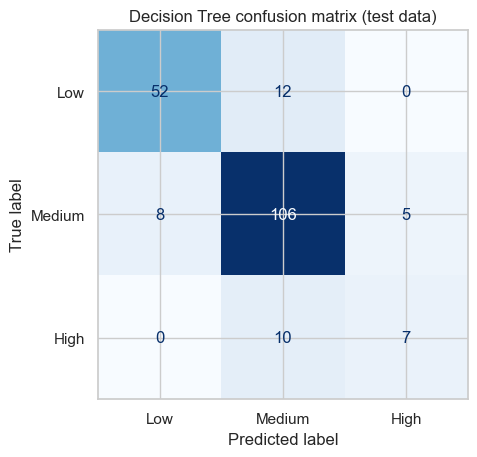


 Random Forest
                  precision    recall  f1-score   support

   Low Fertility       0.93      0.86      0.89        64
Medium Fertility       0.85      0.97      0.91       119
  High Fertility       1.00      0.35      0.52        17

        accuracy                           0.88       200
       macro avg       0.93      0.73      0.77       200
    weighted avg       0.89      0.88      0.87       200



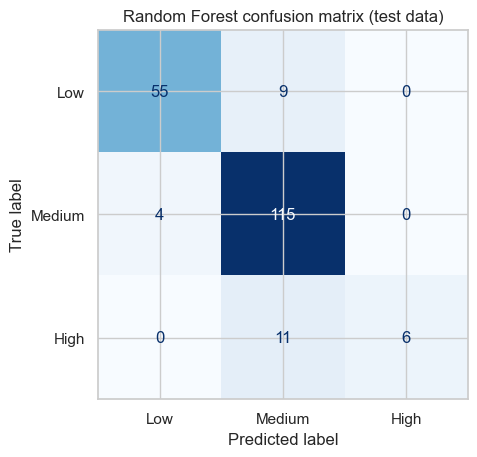


 KNN
                  precision    recall  f1-score   support

   Low Fertility       0.74      0.62      0.68        64
Medium Fertility       0.74      0.87      0.80       119
  High Fertility       0.83      0.29      0.43        17

        accuracy                           0.74       200
       macro avg       0.77      0.60      0.64       200
    weighted avg       0.75      0.74      0.73       200



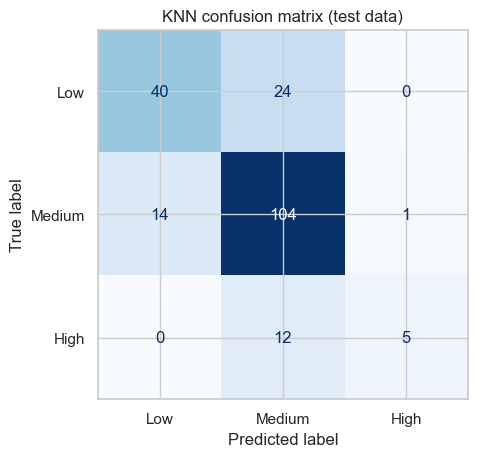


 SVM
                  precision    recall  f1-score   support

   Low Fertility       0.80      0.86      0.83        64
Medium Fertility       0.89      0.83      0.86       119
  High Fertility       0.70      0.82      0.76        17

        accuracy                           0.84       200
       macro avg       0.80      0.84      0.81       200
    weighted avg       0.85      0.84      0.84       200



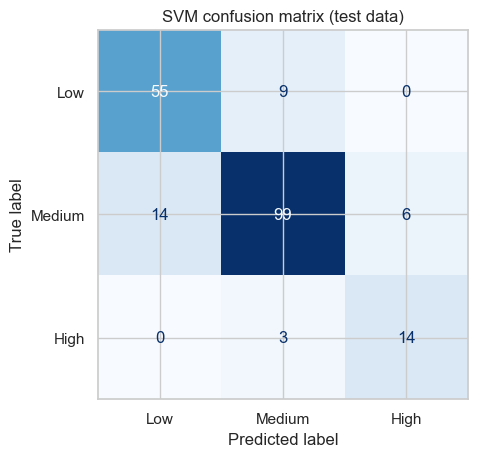

,Model,CV Macro F1,Accuracy,Precision (macro),Recall (macro),F1 (macro)
1,Random Forest,0.7868,0.880,0.9280,0.7262,0.7739
3,SVM,0.7747,0.840,0.7963,0.8383,0.8149
0,Decision Tree,0.7503,0.825,0.7594,0.7050,0.7266
2,KNN,0.5931,0.745,0.7723,0.5977,0.6386


In [10]:
rows = []
for name, pipeline in models.items():
    predictions = pipeline.predict(X_test)
    prec, rec, f1, _ = precision_recall_fscore_support(
        y_test, predictions, average='macro', zero_division=0)
    rows.append({'Model': name, 'CV Macro F1': cv_results[name][0],
                 'Accuracy': accuracy_score(y_test, predictions),
                 'Precision (macro)': prec, 'Recall (macro)': rec, 'F1 (macro)': f1})
    print('\n', name)
    print(classification_report(y_test, predictions, labels=CLASSES, zero_division=0))
    cm = confusion_matrix(y_test, predictions, labels=CLASSES)
    ConfusionMatrixDisplay(cm, display_labels=['Low', 'Medium', 'High']).plot(
        cmap='Blues', values_format='d', colorbar=False)
    plt.title(name + ' confusion matrix (test data)')
    plt.show()
results = pd.DataFrame(rows).sort_values('CV Macro F1', ascending=False)
display(results.round(4))

Selected using training CV: Random Forest
Held-out test metrics:


,Model,CV Macro F1,Accuracy,Precision (macro),Recall (macro),F1 (macro)
1,Random Forest,0.7868,0.88,0.928,0.7262,0.7739


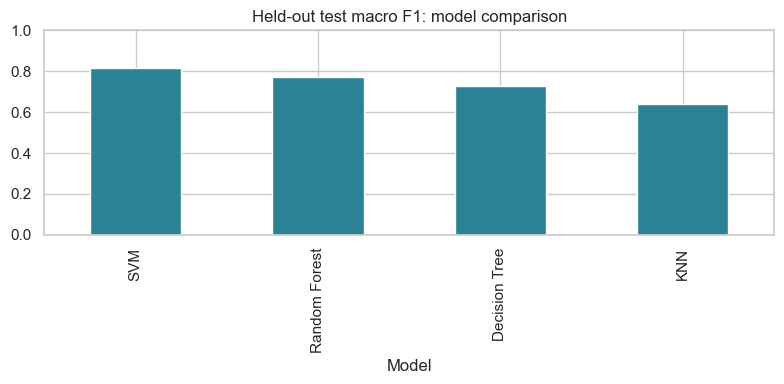

In [11]:
best_name = str(results.iloc[0]['Model'])
best_model = models[best_name]
print('Selected using training CV:', best_name)
print('Held-out test metrics:')
display(results.loc[results['Model'] == best_name].round(4))
results.sort_values('F1 (macro)', ascending=False).plot.bar(
    x='Model', y='F1 (macro)', ylim=(0, 1), legend=False, color='#2b8295', figsize=(8, 4))
plt.title('Held-out test macro F1: model comparison')
plt.tight_layout()
plt.show()

,Feature,Importance,Std
5,Available_K_kg_ha,0.2364,0.0319
2,Organic_Carbon_g_kg,0.2138,0.0346
3,Available_N_kg_ha,0.1805,0.0319
4,Available_P_kg_ha,0.1572,0.0385
1,Electrical_Conductivity_dS_m,0.0048,0.0167
7,Zinc_mg_kg,0.0047,0.0050
11,Copper_mg_kg,0.0005,0.0047
10,Manganese_mg_kg,-0.0002,0.0038
9,Iron_mg_kg,-0.0028,0.0061
8,Boron_mg_kg,-0.0035,0.0052


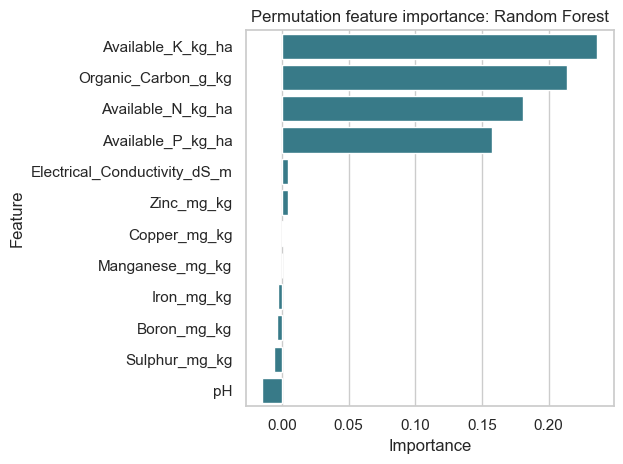

In [12]:
perm = permutation_importance(best_model, X_test, y_test, scoring='f1_macro',
                              n_repeats=15, random_state=42, n_jobs=-1)
importance = pd.DataFrame({'Feature': FEATURES,
                           'Importance': perm.importances_mean,
                           'Std': perm.importances_std}).sort_values('Importance', ascending=False)
display(importance.round(4))
sns.barplot(data=importance, x='Importance', y='Feature', color='#2b8295')
plt.title(f'Permutation feature importance: {best_name}')
plt.tight_layout()
plt.show()

In [13]:
new_soil_sample = X_test.iloc[[0]].copy()  # demonstration only
predicted_class = best_model.predict(new_soil_sample)[0]
print('Input sample:')
display(new_soil_sample)
print('Predicted fertility class:', predicted_class)
print('Actual held-out class (demo check):', y_test.iloc[0])

joblib.dump({'model': best_model, 'features': FEATURES, 'classes': CLASSES},
            'soil_fertility_best_model.joblib')
print('Saved: soil_fertility_best_model.joblib')

Input sample:


,pH,Electrical_Conductivity_dS_m,Organic_Carbon_g_kg,Available_N_kg_ha,Available_P_kg_ha,Available_K_kg_ha,Sulphur_mg_kg,Zinc_mg_kg,Boron_mg_kg,Iron_mg_kg,Manganese_mg_kg,Copper_mg_kg
82,6.17,0.918,8.16,230.85,25.3,198.33,6.39,0.64,0.39,18.4,4.83,0.64


Predicted fertility class: Medium Fertility
Actual held-out class (demo check): Medium Fertility
Saved: soil_fertility_best_model.joblib
